# Project 1, Phase 3: Real data, one drug, one endpoint

This notebook stands alone. You do not need Phase 1 or 2 open.

Drug: Erlotinib. Response: GDSC log IC50 (LN_IC50), one number per cell line. Expression: Sanger merged RNA-seq, log2 scale, which combines Sanger and Broad (CCLE) data, Sanger preferred where a model was analysed twice. Two honest notes up front. First, the DepMap portal itself is bot-walled and GDSC's own basal-expression file is retired, so expression comes from Sanger's merged file instead, matched to GDSC by model ID. Second, GDSC gives one endpoint number per cell line, not a measured time course, so the ODE predicts a growth-inhibition score at a fixed dose and a 2-parameter linear map calibrates it to LN_IC50 units. The curve itself is still the model's internal prediction.

In [1]:
%pip install -q torchdiffeq
import os
import numpy as np
import pandas as pd
import torch
from torchdiffeq import odeint
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge

torch.manual_seed(0)
print("setup done")

Note: you may need to restart the kernel to use updated packages.


setup done


In [2]:
os.makedirs('data', exist_ok=True)
if not os.path.exists('data/GDSC1_fitted_dose_response_24Jul22.csv'):
    !wget -q https://ftp.sanger.ac.uk/pub/project/cancerrxgene/releases/current_release/GDSC1_fitted_dose_response_24Jul22.csv -O data/GDSC1_fitted_dose_response_24Jul22.csv
if not os.path.exists('data/rnaseq_merged_rsem_tpm_20260323.csv'):
    !wget -q https://cog.sanger.ac.uk/cmp/download/rnaseq_merged_20260323.zip -O data/rnaseq_merged_20260323.zip
    !unzip -o -q data/rnaseq_merged_20260323.zip rnaseq_merged_rsem_tpm_20260323.csv -d data
print("files ready")

files ready


In [3]:
gdsc = pd.read_csv('data/GDSC1_fitted_dose_response_24Jul22.csv', usecols=['CELL_LINE_NAME', 'SANGER_MODEL_ID', 'DRUG_NAME', 'LN_IC50'])
erl = gdsc[gdsc['DRUG_NAME'] == 'Erlotinib'].dropna(subset=['LN_IC50']).drop_duplicates('SANGER_MODEL_ID')
print("Erlotinib lines:", len(erl))

tpm = pd.read_csv('data/rnaseq_merged_rsem_tpm_20260323.csv', header=0, low_memory=False)
data = tpm.iloc[3:].copy()
data = data.set_index(data.columns[0])
model_cols = [c for c in data.columns if str(c).startswith('SIDM')]
expr = data[model_cols].apply(pd.to_numeric, errors='coerce')
expr = expr[~expr.index.duplicated(keep='first')]
print("expression genes:", expr.shape[0], "models:", expr.shape[1])

matched_ids = [m for m in erl['SANGER_MODEL_ID'] if m in set(model_cols)]
erl_m = erl.set_index('SANGER_MODEL_ID').loc[matched_ids]
mat = expr[matched_ids].T
print("matched lines:", len(matched_ids), "(check: hundreds, not tens)")
X = mat.values.astype(np.float32)
y = erl_m['LN_IC50'].values.astype(np.float32)
print("X:", X.shape, "y mean:", round(float(y.mean()), 3), "std:", round(float(y.std()), 3))

Erlotinib lines: 393


expression genes: 41144 models: 1898
matched lines: 392 (check: hundreds, not tens)


X: (392, 41144) y mean: 2.519 std: 1.115


In [4]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0)
print("train:", Xtr.shape, "test:", Xte.shape)

keep = np.isnan(Xtr).mean(axis=0) < 0.5
Xtr_k, Xte_k = Xtr[:, keep], Xte[:, keep]
var = np.nanvar(Xtr_k, axis=0)
top = np.argsort(var)[-500:]
Xtr, Xte = Xtr_k[:, top], Xte_k[:, top]
print("top-500 genes selected")

med = np.nanmedian(Xtr, axis=0)
mu, sd = np.nanmean(Xtr, axis=0), np.nanstd(Xtr, axis=0)
sd = np.where(sd == 0, 1.0, sd)
def prep(A):
    A = np.where(np.isnan(A), med, A)
    return ((A - mu) / sd).astype(np.float32)
Xtr, Xte = prep(Xtr), prep(Xte)
print("prepared: train", Xtr.shape, "test", Xte.shape)

train: (313, 41144) test: (79, 41144)


top-500 genes selected
prepared: train (313, 500) test (79, 500)


## The model

Same encoder and ODE as Phase 2, with one fix that mattered. The encoder maps 500 genes to 2 numbers, mapped to positive parameters through a soft bounded exponent: CL = 7.5 * exp(tanh(z)), growth = 0.2 * exp(tanh(z)). A hard clamp killed gradients when outputs saturated, and a free exp exploded to NaN. The tanh version stays bounded (CL about 2.8 to 20.4, growth about 0.07 to 0.54) with gradients that never die completely. The ODE runs 30 days at the fixed Phase 1 dose, and the head predicts LN_IC50 = a + b * log(T30 / T0).

In [5]:
DOSE, V, K, KILL, T0 = 500.0, 50.0, 100.0, 0.05, 10.0
t = torch.linspace(0, 30, 31)
Xtr_t = torch.tensor(Xtr)
Xte_t = torch.tensor(Xte)
ytr_t = torch.tensor(ytr)
yte_t = torch.tensor(yte)

def simulate(CL, growth):
    ke = CL / V
    def ode(tt, yy):
        C, T = yy[:, 0], yy[:, 1]
        return torch.stack([-ke * C, growth * T * (1 - T / K) - KILL * C * T], dim=1)
    y0 = torch.stack([torch.full_like(CL, DOSE / V), torch.full_like(CL, T0)], dim=1)
    return odeint(ode, y0, t, method="rk4", options={"step_size": 1.0})

encoder = torch.nn.Sequential(torch.nn.Linear(500, 32), torch.nn.ReLU(), torch.nn.Linear(32, 2))
a = torch.nn.Parameter(torch.tensor(float(ytr.mean())))
b = torch.nn.Parameter(torch.tensor(-1.0))
opt = torch.optim.Adam(list(encoder.parameters()) + [a, b], lr=0.01)

def predict(Xt):
    raw = encoder(Xt)
    CL = 7.5 * torch.exp(torch.tanh(raw[:, 0]))
    gr = 0.2 * torch.exp(torch.tanh(raw[:, 1]))
    sol = simulate(CL, gr)
    T30 = sol[-1, :, 1]
    return a + b * torch.log(T30 / T0)

for step in range(1001):
    opt.zero_grad()
    loss = ((predict(Xtr_t) - ytr_t) ** 2).mean()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), 1.0)
    opt.step()
    if step % 100 == 0:
        print("step", step, "loss", round(loss.item(), 4))
print("final loss", round(loss.item(), 4))
print("head a, b:", round(a.item(), 3), round(b.item(), 3))

step 0 loss 4.7668


step 100 loss 0.8701


step 200 loss 0.8196


step 300 loss 0.8169


step 400 loss 0.5162


step 500 loss 0.4328


step 600 loss 0.3942


step 700 loss 0.3687


step 800 loss 0.3625


step 900 loss 0.3134


step 1000 loss 0.303
final loss 0.303
head a, b: 3.633 -1.596


Neural ODE train corr: 0.875
Neural ODE test corr: 0.404


Ridge train corr: 0.999
Ridge test corr: 0.322


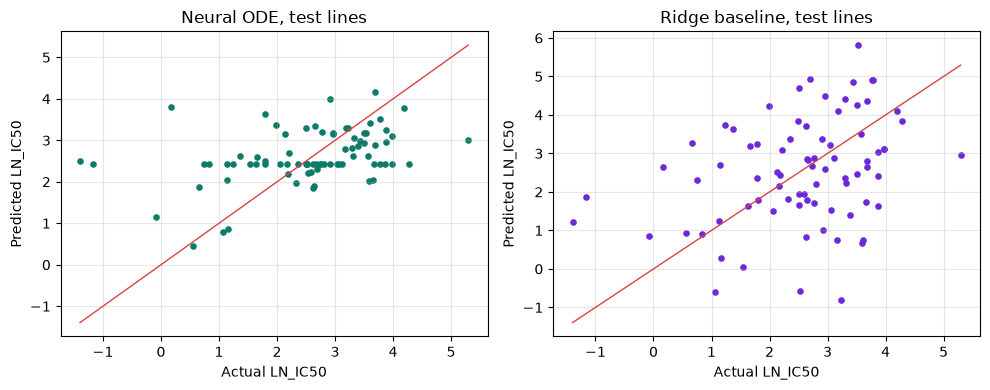

In [6]:
def corr(p, q):
    p = p - p.mean()
    q = q - q.mean()
    return float((p * q).mean() / (p.std() * q.std()))

with torch.no_grad():
    ptr, pte = predict(Xtr_t).numpy(), predict(Xte_t).numpy()
print("Neural ODE train corr:", round(corr(ptr, ytr), 3))
print("Neural ODE test corr:", round(corr(pte, yte), 3))

ridge = Ridge(alpha=1.0).fit(Xtr, ytr)
print("Ridge train corr:", round(corr(ridge.predict(Xtr), ytr), 3))
print("Ridge test corr:", round(corr(ridge.predict(Xte), yte), 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(yte, pte, s=14, color="#0E7A68")
axes[0].plot([yte.min(), yte.max()], [yte.min(), yte.max()], color="#D64545", linewidth=1)
axes[0].set_xlabel("Actual LN_IC50")
axes[0].set_ylabel("Predicted LN_IC50")
axes[0].set_title("Neural ODE, test lines")
axes[0].grid(True, alpha=0.3)
axes[1].scatter(yte, ridge.predict(Xte), s=14, color="#6D28D9")
axes[1].plot([yte.min(), yte.max()], [yte.min(), yte.max()], color="#D64545", linewidth=1)
axes[1].set_xlabel("Actual LN_IC50")
axes[1].set_ylabel("Predicted LN_IC50")
axes[1].set_title("Ridge baseline, test lines")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Check

The honest numbers are the test correlations: Neural ODE versus Ridge, on cell lines neither model trained on. If the Neural ODE is close to or above Ridge, the mechanistic path earns its keep. If Ridge wins clearly, say so: the ODE's value here is the mechanistic story, not beating a flexible regression.

Milestone: real data runs end to end. Save a copy in Drive, then tell Muse to start Phase 4.